# Gold price prediction: what can and cannot be predicted

**Question.** Can I predict tomorrow's gold price from 10 years of daily data, and how would I know if my model is any good?

**Short answer.** Predicting the *price level* looks easy (R² ≈ 0.999) but is a trap. Predicting the *direction or size of tomorrow's return* with simple features does **not** beat a naive baseline. What *can* be predicted is **volatility** (how much the price will move), and a small model beats the naive rule there (error about 12% lower with ridge and about 17% lower with boosting).

Data: `data/gold_prices_10y.csv`, 2,511 daily rows from 2016-01-29 to 2026-01-23 (prices look like a gold ETF, about 107 to 458). All figures below are computed by this notebook.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.grid": True, "grid.alpha": .25})
df = pd.read_csv("data/gold_prices_10y.csv", parse_dates=["Date"]).set_index("Date")
print(df.shape, df.index.min().date(), "to", df.index.max().date())
print("Missing values in price columns:", int(df[["Open","High","Low","Close","Volume"]].isna().sum().sum()))
print("Adj Close differs from Close in", int((df["Close"] != df["Adj Close"]).sum()), "rows (so it adds nothing)")
df[["Close"]].describe().T

(2511, 15) 2016-01-29 to 2026-01-23
Missing values in price columns: 0
Adj Close differs from Close in 0 rows (so it adds nothing)


,count,mean,std,min,25%,50%,75%,max
Close,2511.0,173.210382,63.167433,106.949997,123.645,164.929993,183.399994,458.0


## 1. A first look

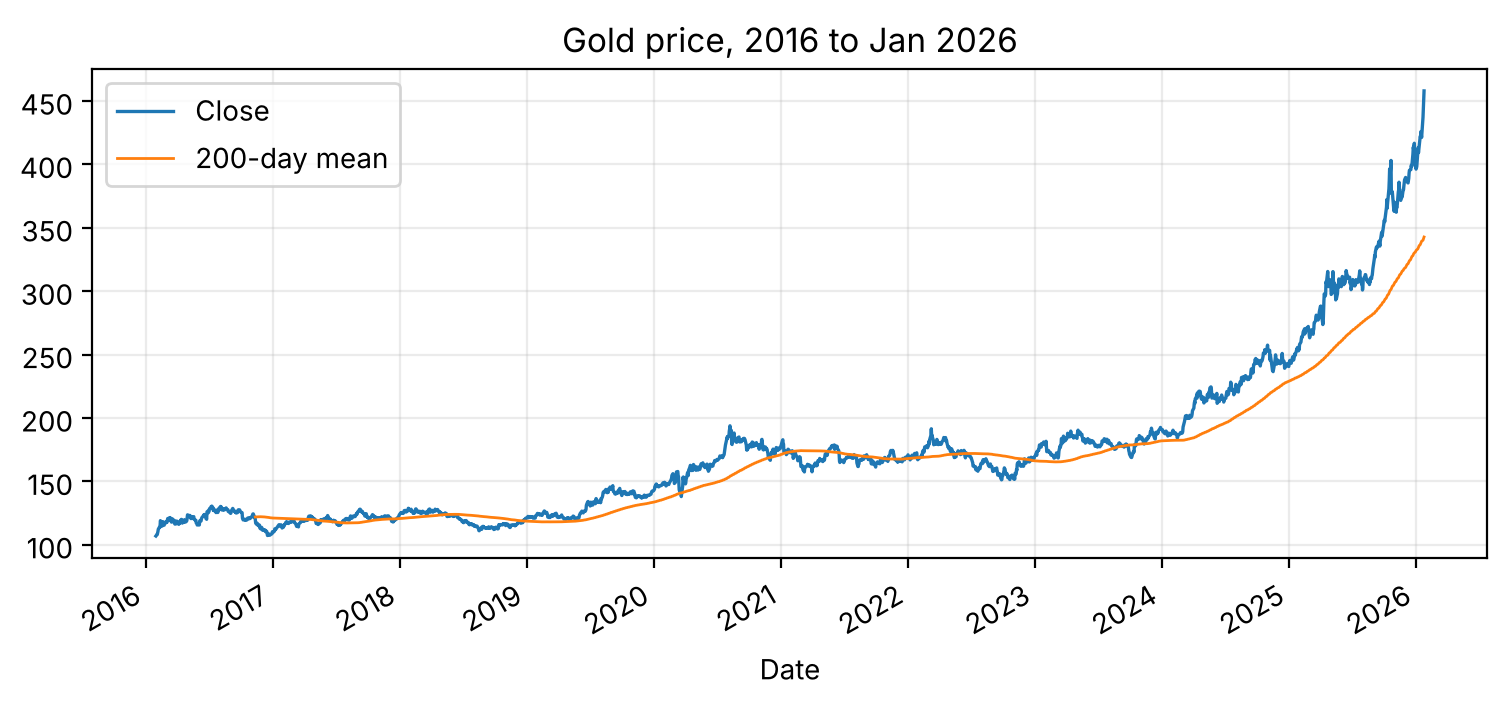

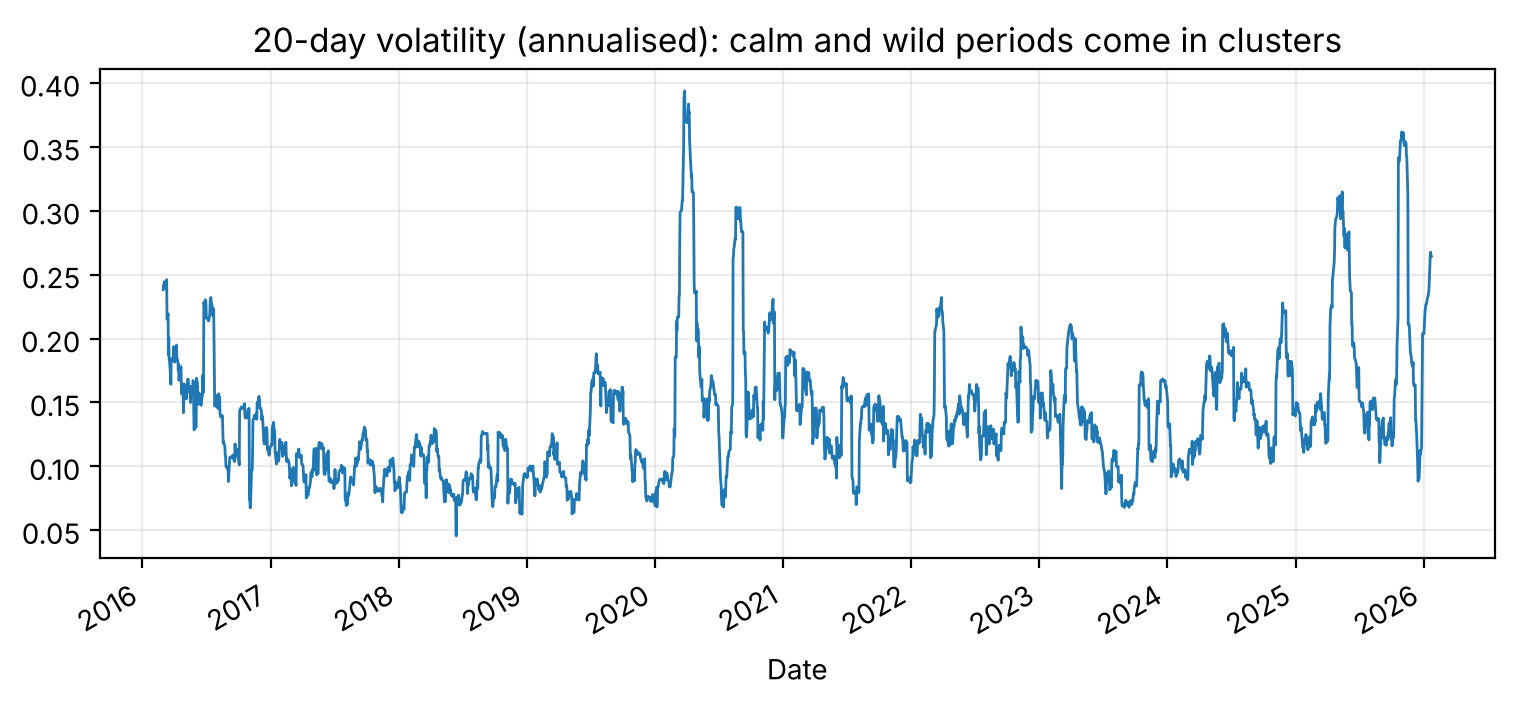

Mean daily return 0.0579%, daily std 0.938%, share of up days 54.0%


In [2]:
fig, ax = plt.subplots()
df["Close"].plot(ax=ax, lw=1.2, label="Close"); df["Close"].rolling(200).mean().plot(ax=ax, lw=1, label="200-day mean")
ax.set_title("Gold price, 2016 to Jan 2026"); ax.legend(); plt.show()

ret = np.log(df["Close"]).diff()
fig, ax = plt.subplots()
(ret.rolling(20).std()*np.sqrt(252)).plot(ax=ax, lw=1)
ax.set_title("20-day volatility (annualised): calm and wild periods come in clusters"); plt.show()
print(f"Mean daily return {ret.mean():.4%}, daily std {ret.std():.3%}, share of up days {np.mean(ret.dropna()>0):.1%}")

Two things to notice. The price trends upward and strongly (especially in the last two years), and volatility comes in **clusters**: quiet periods follow quiet periods. These two facts decide what is predictable.

## 2. The trap: predicting the price level
Predict tomorrow's close with *today's close*, with no model at all.

In [3]:
y, p = df["Close"].iloc[1:], df["Close"].shift(1).iloc[1:]
print(f"R² of 'tomorrow = today' on the price level: {r2_score(y, p):.4f}")

R² of 'tomorrow = today' on the price level: 0.9990


R² of about 0.999 with zero intelligence. Because prices move slowly relative to their range, **any** model on price levels looks excellent. This number says nothing about skill, so I do not use it. I predict **returns** instead and compare every model with a naive baseline.

## 3. Features and a fair test
Every feature uses only information available *before* the day it predicts (lagged returns, moving-average gaps, volatility, range, volume change). The test is **walk-forward**: the model is retrained 12 times on all data before each test block, and tested on the last 3 years (756 days). No random shuffling, so no leakage from the future.

In [4]:
close = df["Close"]; r = np.log(close).diff()
X = pd.DataFrame({f"ret_lag{k}": r.shift(k) for k in (1, 2, 3, 5)})
X["ret_mean5"]  = r.rolling(5).mean().shift(1)
X["ret_mean20"] = r.rolling(20).mean().shift(1)
X["vol20"]      = r.rolling(20).std().shift(1)
X["ma_gap20"]   = (close/close.rolling(20).mean()-1).shift(1)
X["ma_gap50"]   = (close/close.rolling(50).mean()-1).shift(1)
X["ma_gap200"]  = (close/close.rolling(200).mean()-1).shift(1)
X["range"]      = ((df.High-df.Low)/close).shift(1)
X["vol_chg"]    = np.log(df.Volume).diff().shift(1)

def walk_forward(D, target, models, n_test=756, n_folds=12):
    test_idx = D.index[-n_test:]
    out = {m: [] for m in models}; actual = []
    for f in np.array_split(np.arange(n_test), n_folds):
        t0 = test_idx[f[0]]
        tr, te = D[D.index < t0], D.loc[test_idx[f]]
        actual.append(te[target].values)
        for name, make in models.items():
            if make is None: out[name].append(np.full(len(te), np.nan)); continue
            m = make().fit(tr.drop(columns=target), tr[target])
            out[name].append(m.predict(te.drop(columns=target)))
    return test_idx, np.concatenate(actual), {k: np.concatenate(v) for k, v in out.items()}

## 4. Tomorrow's return: does any model beat the naive baseline?

In [5]:
D = pd.concat([X, r.rename("y")], axis=1).dropna()
models = {
 "ridge": lambda: make_pipeline(StandardScaler(), Ridge(alpha=100)),
 "boosting": lambda: GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=.03, subsample=.7, random_state=0),
}
idx, actual, pred = walk_forward(D, "y", models)
rows = [("Predict zero (naive)", np.zeros_like(actual)), ("Ridge", pred["ridge"]), ("Gradient boosting", pred["boosting"])]
tab = pd.DataFrame({
  "RMSE": [np.sqrt(mean_squared_error(actual, p)) for _, p in rows],
  "R² vs zero": [r2_score(actual, p) for _, p in rows],
  "Direction right": [np.mean(np.sign(p) == np.sign(actual)) if p.any() else np.mean(actual > 0) for _, p in rows],
}, index=[n for n, _ in rows])
print(f"Share of up days in the test period: {np.mean(actual>0):.1%} (always guessing 'up' scores this)")
tab.round(4)

Share of up days in the test period: 56.1% (always guessing 'up' scores this)


,RMSE,R² vs zero,Direction right
Predict zero (naive),0.0105,-0.0146,0.5608
Ridge,0.0105,-0.0206,0.4947
Gradient boosting,0.0107,-0.0503,0.5476


Neither model beats the naive baseline: RMSE is the same or slightly worse, R² is about zero or negative, and "direction right" is no better than always guessing "up", which already scores 56% because gold rose over this period. This is the honest finding: **with these features, tomorrow's return is not predictable from past prices.**

### Would trading on it have helped?
A long/flat rule (hold gold only when the model predicts a positive return), before costs, compared with simply holding.

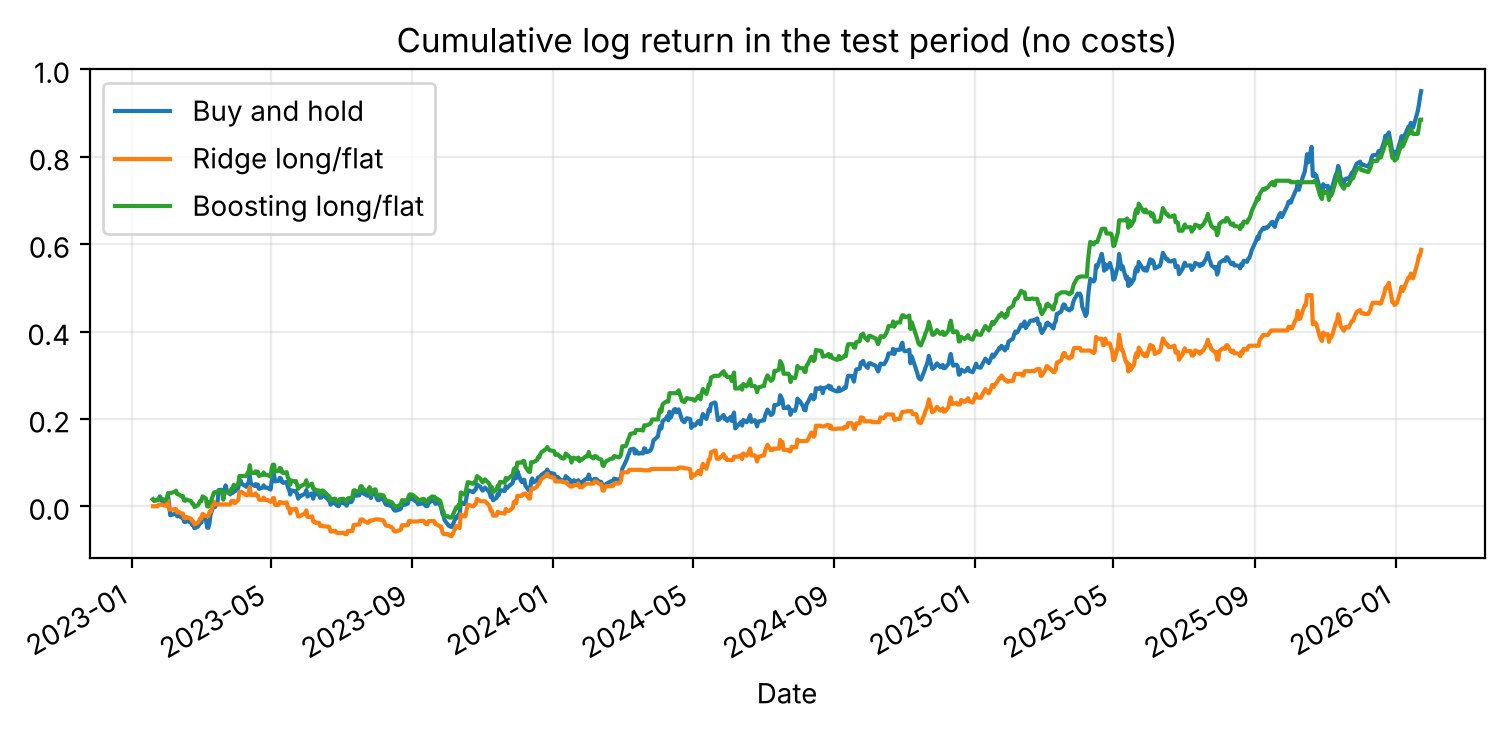

In [6]:
test_ret = pd.Series(actual, index=idx)
def curve(pos): return (pos*test_ret).cumsum()
fig, ax = plt.subplots()
curve(pd.Series(1.0, index=idx)).plot(ax=ax, label="Buy and hold")
curve(pd.Series((pred["ridge"] > 0).astype(float), index=idx)).plot(ax=ax, label="Ridge long/flat")
curve(pd.Series((pred["boosting"] > 0).astype(float), index=idx)).plot(ax=ax, label="Boosting long/flat")
ax.set_title("Cumulative log return in the test period (no costs)"); ax.legend(); plt.show()

In [7]:
for name, pos in [("Buy and hold", pd.Series(1.0, index=idx)), ("Ridge long/flat", pd.Series((pred["ridge"] > 0).astype(float), index=idx)), ("Boosting long/flat", pd.Series((pred["boosting"] > 0).astype(float), index=idx))]:
    print(f"{name:20s} final cumulative log return: {curve(pos).iloc[-1]:.2f}")

Buy and hold         final cumulative log return: 0.95
Ridge long/flat      final cumulative log return: 0.59
Boosting long/flat   final cumulative log return: 0.89


At the end, holding beat both rules. The boosting rule was ahead for much of the period but gave it back in the last months, and one test path of three years is too short to call that an edge, especially since gold rose strongly throughout. Together with the table above, this is a negative result, and I report it as one.

## 5. What can be predicted: volatility
Volatility clusters, so recent volatility says something about the next few days. Target: realised volatility over the *next* 5 days. Baseline: "it will equal the last 20-day volatility".

                           RMSE       R²
Naive: last 20-day vol  0.00493 -0.01856
Ridge                   0.00436  0.20370
Gradient boosting       0.00411  0.29169
Ridge cuts the error by 11.6% versus the naive rule


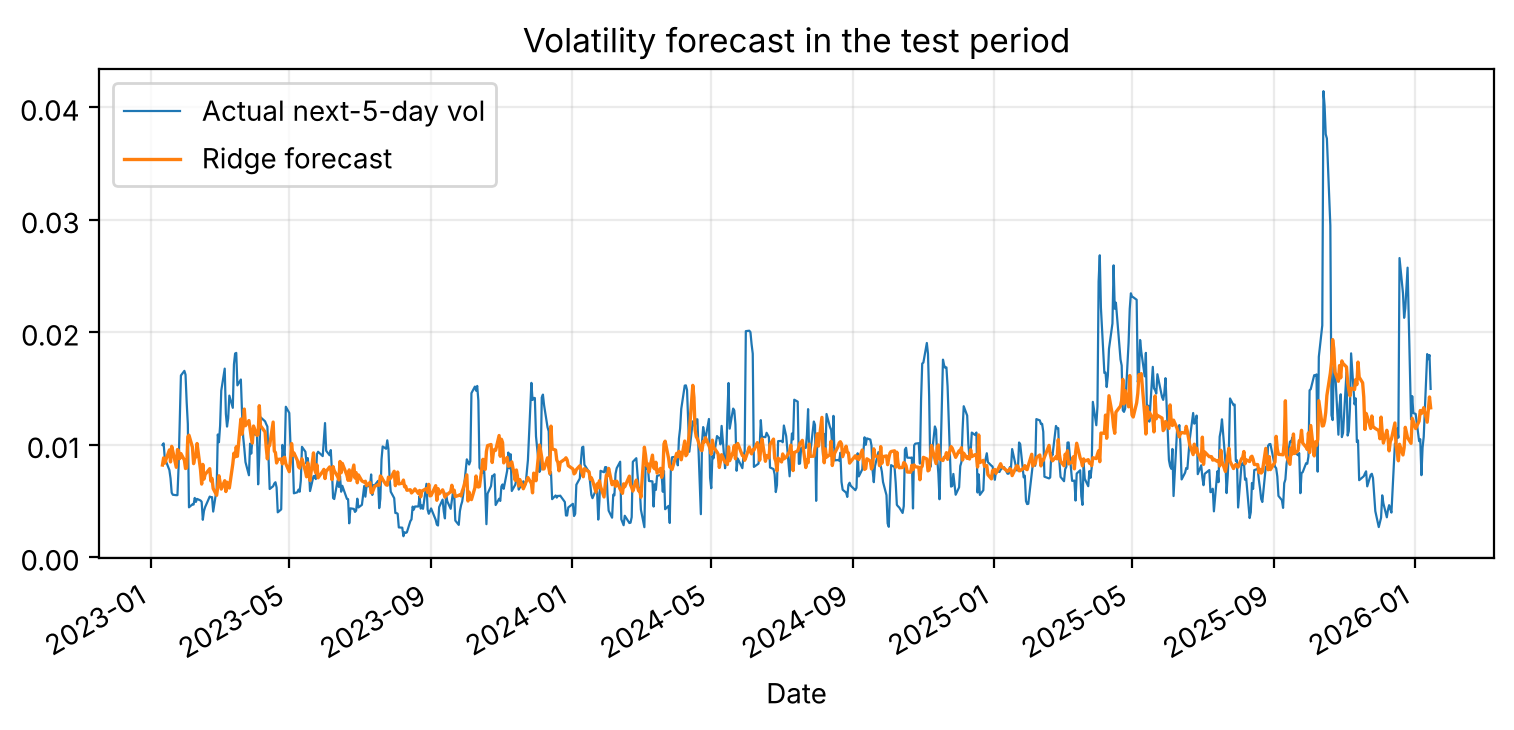

In [8]:
fvol = r.rolling(5).std().shift(-5)          # std of the next 5 returns (the target)
V = pd.concat([X, fvol.rename("y")], axis=1).dropna()
vmodels = {
 "ridge": lambda: make_pipeline(StandardScaler(), Ridge(alpha=10)),
 "boosting": lambda: GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=.03, subsample=.7, random_state=0),
}
vidx, vact, vpred = walk_forward(V, "y", vmodels)
base = V.loc[vidx, "vol20"].values
vt = pd.DataFrame({
  "RMSE": [np.sqrt(mean_squared_error(vact, p)) for p in (base, vpred["ridge"], vpred["boosting"])],
  "R²":   [r2_score(vact, p) for p in (base, vpred["ridge"], vpred["boosting"])],
}, index=["Naive: last 20-day vol", "Ridge", "Gradient boosting"])
print(vt.round(5))
gain = 1 - vt.loc["Ridge","RMSE"]/vt.loc["Naive: last 20-day vol","RMSE"]
print(f"Ridge cuts the error by {gain:.1%} versus the naive rule")
fig, ax = plt.subplots()
pd.Series(vact, index=vidx).plot(ax=ax, lw=.8, label="Actual next-5-day vol")
pd.Series(vpred["ridge"], index=vidx).plot(ax=ax, lw=1.2, label="Ridge forecast")
ax.set_title("Volatility forecast in the test period"); ax.legend(); plt.show()

## 6. What I take from this
- **A high R² on price levels is not skill.** Always compare with a naive baseline, and test on data the model has not seen, in time order.
- **Returns are close to unpredictable from price history alone**, which is what finance theory expects for a liquid market. The simple models did not beat the baseline, and a trading rule built on them would have lost to holding.
- **Volatility is predictable**, and that is useful for risk: position sizing, risk limits and stress tests do not need to guess the direction.

**Limits.** One asset, one period (a long gold rally), no transaction costs, features from prices only. The data ends in January 2026. Next steps: add macro variables (dollar index, real yields), add costs to the trading test, and test more robust volatility models such as GARCH.